# Test 2 · Figure 2·Table 2 재현

논문 §5의 Test 2의 해를 C++로 계산한다. 먼저 $N=M=64$에서 옵션 가격의 표면과 시간 단면을 그린 뒤, $M=1024$를 고정하고 공간 격자를 세분하여 Table 2의 오차와 관측 수렴률을 재현한다.

## 실험 설정

$$T=1,\quad r=0.06,\quad K=25,\quad S_{\max}=100,\quad \varepsilon=10^{-4},$$
$$\sigma(x,t)=0.4(2+\sin x),\qquad \alpha=0.16,\qquad \beta^*=0.06.$$

$\alpha$와 $\beta^*$는 계수의 최선의 하한·상한으로 선택했다. 공간은 논문 §3의 piecewise uniform mesh와 central difference, 시간은 implicit Euler를 사용한다. $U_i^M=\pi_\varepsilon(x_i-K)$에서 시작하여 $j=M-1,\ldots,0$으로 진행한다.

사용하는 결과는 Lemma 1의 M-matrix 안정성 기준과 Theorem 1의 공간 2차 수렴 주장이다. 증명은 생략하고 관측값을 비교한다. 비균일 격자 접합점에서는 국소 절단오차에 주의가 필요하다.

이 노트북은 다른 노트북을 실행하지 않아도 독립적으로 실행된다. 커널은 `C++17 (Black–Scholes, xeus-cpp)`, 작업 디렉터리는 `ipynb/`이다.

In [1]:
#include <cstdio>
#include <cmath>
#include <chrono>
#include "../include/BlackScholesSolver.h"
#include "../include/ErrorAnalysis.h"
#include "../include/ExperimentOutput.h"
#include "../include/NotebookDisplay.h"

prepareOutput();
printf("C++17 | xeus-cpp | central difference + implicit Euler + Thomas\n");

C++17 | xeus-cpp | central difference + implicit Euler + Thomas


## Figure 2 · 계산된 옵션 가격

$N=M=64$에서 $65\times65$개 격자값을 모두 계산한다. 그림의 시간축은 잔존만기 대신 원래 좌표 $t\in[0,T]$이다. 원문의 표면도와 같은 수치 설정을 사용하며, strike 주변 시간 단면을 추가로 그려 가격 변화를 읽는다.

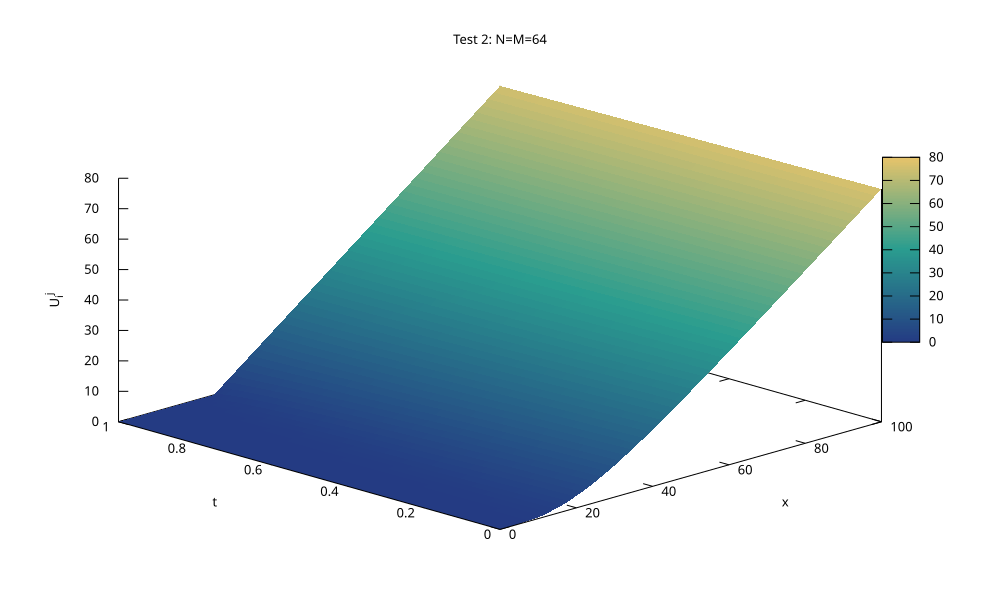

N=64, M=64, epsilon=1.0e-04, alpha=0.16, beta*=0.06
U(K,0)=6.8258198569, minimum U=0.00000000e+00
j=0: max interior off-diagonal=-1.27570878e-01, min dominance margin=6.40599976e+01


In [2]:
BlackScholesSolver figure(64, 64, 0.16, 0.06);
figure.solveTest2();
printf("N=%d, M=%d, epsilon=%.1e, alpha=%.2f, beta*=%.2f\n",
       figure.N, figure.M, figure.epsilon, figure.alpha, figure.betaStar);
printf("U(K,0)=%.10f, minimum U=%.8e\n", figure.value(figure.N/4,0), ErrorAnalysis::minimumValue(figure));
printf("j=0: max interior off-diagonal=%.8e, min dominance margin=%.8e\n",
       figure.largestInteriorOffDiagonal(), figure.minimumDiagonalMargin());
plotSolution(figure, "test2", "Test 2");
displaySVG("../results/test2_surface.svg");

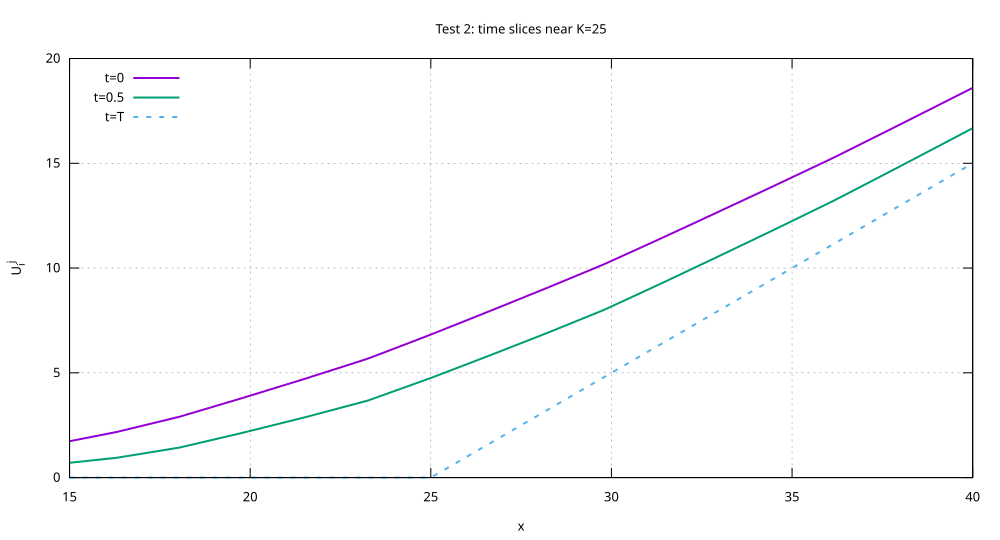

In [3]:
displaySVG("../results/test2_slices.svg");

표면도는 전체 가격 범위를, 단면도는 $K=25$ 주변의 변화를 보여준다. 만기에서는 smoothing된 payoff로 돌아가며, 만기 전에는 strike 부근에서 시간가치가 나타난다. 그림에서 보이는 진동 여부와 별도로 내부 행렬 계수와 최솟값을 출력했다. 한 그림만으로 모든 매개변수에서의 안정성이 입증되는 것은 아니다.

## 기준해 · $U^{2048,1024}$

이 문제의 정확해는 알려져 있지 않으므로 논문과 동일하게 $N_{\rm ref}=2048$, $M=1024$인 수치해를 참조해로 사용한다. 전체 시간 이력을 보관하며, coarse grid와 같은 시간층 $t_j$에서 **공간 선형 보간**한다.

$$\bar U(x,t_j)=\frac{x_{k+1}^{\rm ref}-x}{x_{k+1}^{\rm ref}-x_k^{\rm ref}}U_k^{j,\rm ref}
+\frac{x-x_k^{\rm ref}}{x_{k+1}^{\rm ref}-x_k^{\rm ref}}U_{k+1}^{j,\rm ref}.$$

공간 격자는 서로 nested라고 가정하지 않는다. 시간 격자는 동일하므로 시간 보간이 필요하지 않다.

In [4]:
const int M = 1024;
const int Nref = 2048;
auto referenceStart = std::chrono::steady_clock::now();
BlackScholesSolver reference(Nref, M, 0.16, 0.06);
reference.solveTest2();
double referenceSeconds = std::chrono::duration<double>(std::chrono::steady_clock::now()-referenceStart).count();
printf("Reference: N=%d, M=%d, %.3f seconds, U history %.2f MiB\n",
       Nref, M, referenceSeconds, (Nref+1.0)*(M+1.0)*sizeof(double)/(1024.0*1024.0));

Reference: N=2048, M=1024, 0.035 seconds, U history 16.02 MiB


## Table 2 · 공간 격자 세분

$$e^{N,M}=\max_{i,j}|U_i^j-\bar U(x_i,t_j)|,\qquad
\bar r^{N,M}=\log_2\left(\frac{e^{N,M}}{e^{2N,M}}\right).$$

$M=1024$를 고정하고 $N=128,256,512,1024$를 계산한다. 오차를 최대화하는 $(x_i,t_j)$도 함께 기록하여 $t=0$만 검사하는 실수를 피한다. 아래 `paperErrors`는 원문에 인쇄된 비교용 값이며, `errors`는 C++ 풀이와 보간으로 새로 계산한다.

In [5]:
const int count = 4;
int nValues[count] = {128, 256, 512, 1024};
double paperErrors[count] = {5.7124e-02, 1.9498e-02, 5.1550e-03, 1.0586e-03};
double errors[count];
double errorX[count];
double errorTime[count];
for(int k=0; k<count; k++)
{
    BlackScholesSolver coarse(nValues[k], M, 0.16, 0.06);
    coarse.solveTest2();
    int iMax = 0;
    int jMax = 0;
    errors[k] = ErrorAnalysis::maxError(coarse, reference, &iMax, &jMax);
    errorX[k] = coarse.x[iMax];
    errorTime[k] = jMax*coarse.tau;
}

printf("   M     N       computed e      paper e     rate      x at max     t at max\n");
FILE* errorFile = openOutput("../results/test2_errors.csv");
fprintf(errorFile, "N,error,rate,paper_error,x_at_max,t_at_max\n");
for(int k=0; k<count; k++)
{
    printf("%4d %5d   %14.8e  %11.4e  ", M, nValues[k], errors[k], paperErrors[k]);
    fprintf(errorFile, "%d,%.17g,", nValues[k], errors[k]);
    if(k+1<count)
    {
        double rate = log(errors[k]/errors[k+1])/log(2.0);
        printf("%7.3f", rate);
        fprintf(errorFile, "%.17g", rate);
    }
    else printf("%7s", "-");
    printf("   %11.6f   %10.7f\n", errorX[k], errorTime[k]);
    fprintf(errorFile, ",%.17g,%.17g,%.17g\n", paperErrors[k], errorX[k], errorTime[k]);
}
fclose(errorFile);

   M     N       computed e      paper e     rate      x at max     t at max
1024   128   5.71239536e-02   5.7124e-02    1.551     25.000100    0.9990234
1024   256   1.94981844e-02   1.9498e-02    1.919     25.000100    0.9990234
1024   512   5.15498502e-03   5.1550e-03    2.284     25.000100    0.9990234
1024  1024   1.05863181e-03   1.0586e-03        -     25.000100    0.9990234


### 원문 수치와 비교

원문 Table 2의 수렴률은 $1.551,\ 1.919,\ 2.284$이다. 인쇄된 오차는 유효숫자 다섯 자리이므로 아래에서는 상대 차이와 **인쇄 반올림 단위 안에 들어오는지**를 함께 확인한다. 계산된 값으로 원문 값을 덮어쓰지 않는다.

In [6]:
printf("    N   relative difference to printed value      rounded match\n");
for(int k=0; k<count; k++)
{
    double halfUnit = 0.5*pow(10.0, floor(log10(paperErrors[k]))-4.0);
    double relative = fabs(errors[k]-paperErrors[k])/paperErrors[k];
    bool matches = fabs(errors[k]-paperErrors[k]) <= halfUnit + 2e-10;
    printf("%5d                  %12.4e                 %s\n",
           nValues[k], relative, matches ? "yes" : "NO");
}

    N   relative difference to printed value      rounded match
  128                    8.1249e-07                 yes
  256                    9.4590e-06                 yes
  512                    2.9068e-06                 yes
 1024                    3.0048e-05                 yes


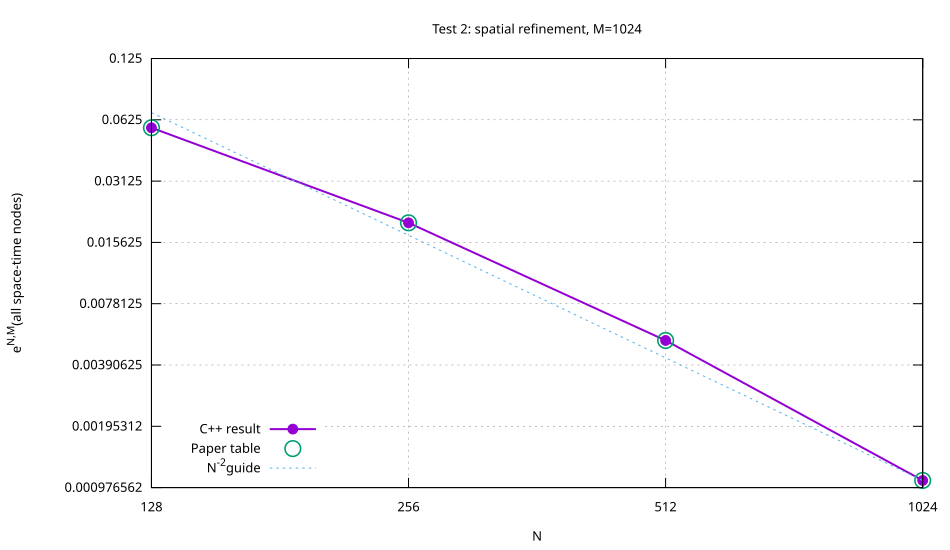

In [7]:
plotConvergence("test2", "Test 2");
displaySVG("../results/test2_convergence.svg");

## 결과 해석

- 네 격자의 오차와 세 수렴률이 원문 Table 2의 인쇄 정밀도와 일치한다.
- $N=512\to1024$에서 관측 수렴률은 약 **2.284**이다. 공간 세분에 따라 오차가 줄어드는 양상을 Theorem 1의 공간 2차 수렴 주장과 비교한다.
- 최대오차가 strike 근방의 만기 직전 시간층에서 발생한다. 따라서 현재 가격 $U_i^0$만 비교하면 논문의 $e^{N,M}$와 다른 양을 측정하게 된다.
- $M$을 함께 세분하지 않았으므로 이 표에서 시간 1차 수렴률을 읽을 수는 없다. $U^{2048,1024}$도 수치해이므로 수렴률은 유한 참조격자의 영향을 받는다. 특히 마지막 수렴률이 2보다 크다는 사실만으로 방법의 차수가 2보다 높다고 결론 내리지 않는다.

결과 파일은 `results/test2_errors.csv`와 `results/test2_slices.csv`에 저장된다. 옵션 가격과 수렴 그림은 같은 폴더에 SVG·PNG로 저장된다. 저장된 결과는 이 노트북의 C++ 셀을 다시 실행하면 갱신된다.